# Etapa 0. Ingesta y buffer (cola FIFO)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 0 es la puerta de entrada del pipeline. Recibe un flujo continuo de eventos de comercio electrónico y lo guarda temporalmente en un buffer FIFO. Después entrega esos eventos a la etapa 1 en micro-lotes. El buffer desacopla la velocidad del productor (el generador de eventos) de la velocidad del consumidor (el preprocesamiento). Cuando el consumidor es más lento, el buffer se llena y el productor espera. Este mecanismo se llama backpressure.

## Pasos del notebook

1. Configuración, importada de `src/config.py`.
2. Lectura de las reseñas como stream, desde un Parquet y dentro de una ventana reciente.
3. Carga del catálogo de productos (precio, categoría y título).
4. Generador sintético de eventos de comercio electrónico.
5. Implementación propia de la cola FIFO (buffer circular y lista enlazada).
6. Buffer con backpressure y formación de micro-lotes.
7. Ejecución de la etapa 0 y métricas observadas.
8. Experimentos de complejidad (en `notebooks/experimentos_complejidad.ipynb`).
9. Salida de la etapa 0 para la etapa 1.

## Paso 1. Configuración

La categoría, las rutas de los datos, la semilla y el tamaño del experimento están en `src/config.py`, el único lugar del proyecto donde se escriben. Este notebook los importa.

- Los datos se generan con `notebooks/00-download-data.ipynb`. Ese notebook deja en `data/raw/` las reseñas de `Office_Products` ordenadas por `timestamp` y los metadatos de productos, ambos en Parquet.
- `SEED = 42` hace que el generador produzca siempre los mismos eventos.
- `N_RESENAS = 1 500 000` es el tamaño de la ventana de reseñas. El enunciado pide un stream de 10 millones de eventos, y en esta ventana el generador produce unos 7 registros por reseña, así que 1 500 000 reseñas dan unos 10.5 millones de eventos.
- `RAIZ` es la carpeta raíz del proyecto. Se busca subiendo desde la carpeta actual hasta encontrar la que contiene `notebooks/` y `data/`, para poder importar `src/` aunque el notebook se abra desde otra ubicación.
- Los resultados de los experimentos se guardan en `results/etapa_0/` y la salida de la etapa en `data/interim/<CATEGORIA>/`. Los archivos que dependen de los datos llevan la categoría en el nombre.

In [1]:
import gc
import inspect
import json
import platform
import statistics
import sys
import threading
import time
import tracemalloc
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

SEED = config.SEED
CATEGORIA = config.CATEGORIA
RUTA_RESENAS = config.RUTA_RESENAS
RUTA_META = config.RUTA_META
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_0"
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_INTERIM.mkdir(parents=True, exist_ok=True)

assert RUTA_RESENAS.exists(), "Faltan las reseñas en Parquet. Ejecutar antes notebooks/00-download-data.ipynb"
assert RUTA_META.exists(), "Faltan los metadatos en Parquet. Ejecutar antes notebooks/00-download-data.ipynb"

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
print(f"Categoría: {CATEGORIA}   ventana: {config.N_RESENAS:,} reseñas   "
      f"tardíos: {config.PORCENTAJE_TARDIOS:.0%}, hasta {config.RETRASO_MAX_TARDIOS_S} s")
PLATAFORMA

Categoría: Office_Products   ventana: 1,500,000 reseñas   tardíos: 5%, hasta 120 s


{'sistema': 'Windows-11-10.0.26200-SP0',
 'procesador': 'Intel64 Family 6 Model 158 Stepping 10, GenuineIntel',
 'nucleos': 12,
 'ram_gb': 17.0,
 'python': '3.12.3',
 'semilla': 42}

## Paso 2. Las reseñas como stream

Las reseñas están en un Parquet de unos 12.8 millones de filas, ordenadas por `timestamp`. No se cargan completas. Se leen con `ParquetFile.iter_batches`, que entrega bloques de 10 000 filas y solo las columnas necesarias, y un **generador** de Python (`yield`) entrega las reseñas una a la vez. La memoria usada depende del tamaño del bloque y no del número de reseñas.

### Ventana reciente

El pipeline usa las **últimas** 1 500 000 reseñas del archivo (`N_RESENAS`), que forman un bloque continuo al final de las reseñas ordenadas por tiempo. Son las más recientes, así que representan el comportamiento actual de la tienda, y al ser un bloque continuo conservan el orden temporal real del stream.

Un Parquet se divide en **grupos de filas** (*row groups*), y sus metadatos guardan cuántas filas tiene cada grupo. Con esos metadatos se calcula en qué grupo empieza la ventana sin leer ningún dato. Los grupos anteriores no se leen, y dentro del primer grupo se descartan las filas previas al inicio de la ventana.

### Por qué un stream y no una lista

- El disco y la RAM son recursos distintos. El archivo ocupa disco, pero procesarlo completo en una lista ocuparía RAM, que es más escasa.
- Un stream real no tiene fin, así que no es posible cargar todo y procesarlo después.
- La memoria del generador es O(1) respecto al número de reseñas, mientras que una lista ocupa O(n).
- Los resultados salen desde el primer registro, lo que reduce la latencia.

La lectura está implementada en `src/etapa_0/generator.py` (`describir_ventana` y `leer_resenas`).

In [2]:
from src.etapa_0.generator import describir_ventana, leer_resenas

# Qué filas y grupos de filas se leen, calculado solo con los metadatos del Parquet
v = describir_ventana()
display(pd.Series({"filas del archivo": v["total_filas"], "inicio de la ventana": v["inicio"],
                   "fin de la ventana": v["fin"], "reseñas": v["filas"],
                   "grupos de filas del archivo": v["grupos_totales"],
                   "grupos que se leen": len(v["grupos_leidos"]),
                   "filas descartadas del primer grupo": v["filas_a_descartar"]}, name="ventana").to_frame())

# Ejemplo: las tres primeras reseñas de la ventana
for resena in leer_resenas(limite=3):
    print(resena)

,ventana
filas del archivo,12845712
inicio de la ventana,11345712
fin de la ventana,12845712
reseñas,1500000
grupos de filas del archivo,65
grupos que se leen,9
filas descartadas del primer grupo,145712


{'user_id': 'AGKOQYR6KUZTPQUHSJ7TPXFDJY2Q', 'parent_asin': 'B002KNHQP2', 'rating': 5.0, 'verified_purchase': True, 'timestamp': 1656697223723}
{'user_id': 'AG5BP2GGBLM44U7Z2TKGFKVTOIGA', 'parent_asin': 'B0BLWF9NFZ', 'rating': 5.0, 'verified_purchase': True, 'timestamp': 1656697225964}
{'user_id': 'AHGI2IUV7HPYW4SUXY7EJAKBS7RQ', 'parent_asin': 'B09KR87M74', 'rating': 5.0, 'verified_purchase': True, 'timestamp': 1656697227568}


### Comprobación empírica: generador frente a lista

Se mide la memoria pico con `tracemalloc` al recorrer 100 000 reseñas de dos formas. La primera usa el generador y la segunda guarda todo en una lista antes de recorrerla. El número de reseñas leídas es el mismo en ambos casos.

In [3]:
def memoria_pico_mb(funcion):
    """Ejecuta funcion() y devuelve la memoria pico (MB) registrada por tracemalloc."""
    gc.collect()
    tracemalloc.start()
    funcion()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1e6


N_PRUEBA = 100_000

def recorrer_con_generador():
    total = 0
    for _ in leer_resenas(limite=N_PRUEBA):
        total += 1
    return total

def recorrer_con_lista():
    todas = list(leer_resenas(limite=N_PRUEBA))   # todo queda en RAM
    total = 0
    for _ in todas:
        total += 1
    return total

pico_gen = memoria_pico_mb(recorrer_con_generador)
pico_lista = memoria_pico_mb(recorrer_con_lista)
print(f"Memoria pico con generador: {pico_gen:8.2f} MB")
print(f"Memoria pico con lista:     {pico_lista:8.2f} MB")
print(f"La lista usa {pico_lista / pico_gen:.0f} veces más memoria para {N_PRUEBA:,} reseñas.")

Memoria pico con generador:     4.26 MB
Memoria pico con lista:        38.86 MB
La lista usa 9 veces más memoria para 100,000 reseñas.


### Rendimiento al crecer el número de reseñas

La comprobación anterior usa un solo tamaño. Para ver cómo escala cada forma de lectura se repite con 1K, 10K, 50K, 100K y 200K reseñas y se miden tres cosas.

- **Memoria pico** con `tracemalloc`. Con la lista se espera O(n), porque guarda todas las reseñas; con el generador, O(1), porque guarda una sola a la vez.
- **Tiempo hasta el primer registro**, es decir, cuánto tarda el consumidor en tener el primer registro para procesar. Es la latencia de arranque del pipeline. La lista debe leer el archivo completo antes de entregar algo; el generador entrega el primero tras leer una línea.
- **Tiempo total** de recorrer todas las reseñas. Sirve para comprobar que el generador no paga su ahorro de memoria con más tiempo.

La memoria se mide en una ejecución aparte de los tiempos, porque `tracemalloc` hace más lento el código que observa. Los tiempos son el promedio de 5 repeticiones. Los resultados se guardan en `results/etapa_0/etapa0_stream_vs_lista_<CATEGORIA>.csv` y se reutilizan si el archivo existe; para medir de nuevo se cambia `REEJECUTAR_STREAM` a `True`.

Resultados leídos de results\etapa0_stream_vs_lista_Office_Products.csv


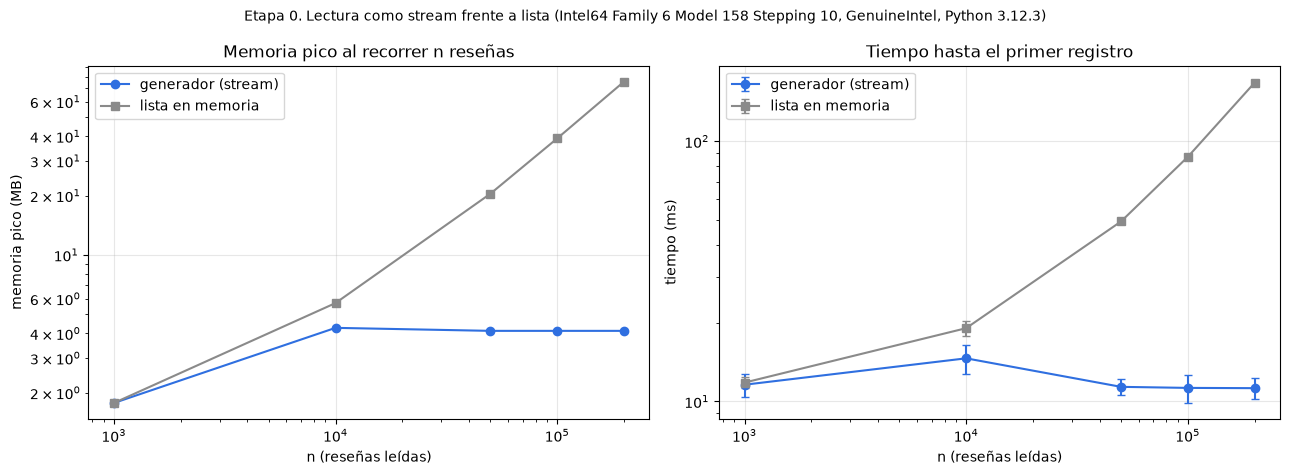

memoria_pico_mb         primer_registro_ms            total_s       
forma        generador   lista          generador    lista generador  lista
n                                                                          
1000             1.772   1.772             11.598   11.818     0.012  0.012
10000            4.264   5.698             14.651   19.128     0.028  0.019
50000            4.117  20.456             11.382   49.184     0.051  0.050
100000           4.117  39.012             11.278   87.066     0.086  0.088
200000           4.117  75.689             11.251  167.696     0.170  0.179

Con 200,000 reseñas:
  memoria pico:         lista 75.7 MB, generador 4.12 MB (18 veces menos)
  primer registro:      lista 168 ms, generador 11.251 ms
  recorrido completo:   lista 0.18 s, generador 0.17 s


In [4]:
REEJECUTAR_STREAM = False
TAMANOS_STREAM = [1_000, 10_000, 50_000, 100_000, 200_000]
REPETICIONES_STREAM = 5
ruta_stream = CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.csv"


def primer_registro(forma, n):
    """Segundos hasta tener el primer registro disponible para procesar."""
    t0 = time.perf_counter()
    if forma == "generador":
        lector = leer_resenas(limite=n)
        next(lector)                       # basta leer una línea
        lector.close()                     # cierra el archivo sin leer el resto
    else:
        todas = list(leer_resenas(limite=n))   # hay que leer todo antes
        todas[0]
    return time.perf_counter() - t0


def recorrido_completo(forma, n):
    """Segundos para recorrer las n reseñas."""
    t0 = time.perf_counter()
    fuente = leer_resenas(limite=n) if forma == "generador" else list(leer_resenas(limite=n))
    for _ in fuente:
        pass
    return time.perf_counter() - t0


def pico_de(forma, n):
    """Memoria pico (MB) al recorrer las n reseñas."""
    def recorrer():
        fuente = leer_resenas(limite=n) if forma == "generador" else list(leer_resenas(limite=n))
        for _ in fuente:
            pass
    return memoria_pico_mb(recorrer)


if ruta_stream.exists() and not REEJECUTAR_STREAM:
    stream_vs_lista = pd.read_csv(ruta_stream)
    print(f"Resultados leídos de {ruta_stream.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS_STREAM:
        for forma in ["generador", "lista"]:
            primeros = [primer_registro(forma, n) for _ in range(REPETICIONES_STREAM)]
            totales = [recorrido_completo(forma, n) for _ in range(REPETICIONES_STREAM)]
            filas.append({"forma": forma, "n": n,
                          "memoria_pico_mb": pico_de(forma, n),
                          "primer_registro_ms": statistics.mean(primeros) * 1000,
                          "primer_registro_desv_ms": statistics.stdev(primeros) * 1000,
                          "total_s": statistics.mean(totales),
                          "total_desv_s": statistics.stdev(totales)})
        print(f"n = {n:>7,} medido")
    stream_vs_lista = pd.DataFrame(filas)
    stream_vs_lista.to_csv(ruta_stream, index=False)

# --- Gráficas -------------------------------------------------------------------
estilo = {"generador": dict(marker="o", color="#2f6fe0", label="generador (stream)"),
          "lista": dict(marker="s", color="#8a8a8a", label="lista en memoria")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for forma, datos in stream_vs_lista.groupby("forma"):
    ax1.plot(datos["n"], datos["memoria_pico_mb"], **estilo[forma])
    ax2.errorbar(datos["n"], datos["primer_registro_ms"], yerr=datos["primer_registro_desv_ms"],
                 capsize=3, **estilo[forma])

for ax, titulo, ylabel in [
        (ax1, "Memoria pico al recorrer n reseñas", "memoria pico (MB)"),
        (ax2, "Tiempo hasta el primer registro", "tiempo (ms)")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (reseñas leídas)"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()

plt.suptitle(f"Etapa 0. Lectura como stream frente a lista ({PLATAFORMA['procesador']}, "
             f"Python {PLATAFORMA['python']})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.png", dpi=150)
plt.show()

# --- Tabla y razones ---------------------------------------------------------------
tabla = stream_vs_lista.pivot(index="n", columns="forma",
                              values=["memoria_pico_mb", "primer_registro_ms", "total_s"]).round(3)
display(tabla)

mayor = stream_vs_lista[stream_vs_lista["n"] == max(TAMANOS_STREAM)].set_index("forma")
print(f"Con {max(TAMANOS_STREAM):,} reseñas:")
print(f"  memoria pico:         lista {mayor.loc['lista', 'memoria_pico_mb']:.1f} MB, "
      f"generador {mayor.loc['generador', 'memoria_pico_mb']:.2f} MB "
      f"({mayor.loc['lista', 'memoria_pico_mb'] / mayor.loc['generador', 'memoria_pico_mb']:.0f} veces menos)")
print(f"  primer registro:      lista {mayor.loc['lista', 'primer_registro_ms']:.0f} ms, "
      f"generador {mayor.loc['generador', 'primer_registro_ms']:.3f} ms")
print(f"  recorrido completo:   lista {mayor.loc['lista', 'total_s']:.2f} s, "
      f"generador {mayor.loc['generador', 'total_s']:.2f} s")

### Lectura de las gráficas

Los valores citados corresponden a la ejecución guardada en `results/etapa_0/`, con reseñas de `Office_Products` y Python 3.12.

- **Memoria.** Con la lista, la memoria pico crece en proporción a n, de 1.8 MB con 1K reseñas a 75.7 MB con 200K, unos 370 bytes por reseña. En escala log-log es una recta de pendiente cercana a 1, es decir, O(n). Con el generador se mantiene entre 4.1 y 4.3 MB desde 10K reseñas, es decir, O(1). Esos 4 MB son el bloque de 10 000 filas que se lee del Parquet. Con 1K reseñas las dos formas usan lo mismo porque el bloque ya contiene todas las reseñas. Con 200K reseñas la lista usa 18 veces más memoria, y la diferencia sigue creciendo con n.
- **Latencia.** Con la lista, el primer registro está disponible solo después de leer todas las reseñas, y esa espera crece de 12 ms con 1K a 168 ms con 200K. Con el generador el primer registro está listo en 11 a 15 ms en todos los tamaños, el tiempo de leer y descomprimir el primer bloque. En un stream que no termina, la lista nunca entregaría el primer registro.
- **Tiempo total.** Recorrer las 200K reseñas toma 0.17 s con el generador y 0.18 s con la lista. El generador no paga su ahorro de memoria con más tiempo, porque las dos formas hacen el mismo trabajo de lectura.

Estas mediciones respaldan la decisión de leer el dataset como stream, por bloques y dentro de una ventana.

## Paso 3. Catálogo de productos

Las reseñas no traen precio, categoría ni título del producto. Esos datos están en el Parquet de metadatos, que se une con las reseñas mediante `parent_asin`. Se leen solo cuatro columnas (`parent_asin`, `price`, `main_category` y `title`) con `pq.read_table(columns=...)`, y se construye un diccionario `parent_asin → (precio, categoría, título)`.

El catálogo sí se carga en memoria porque es una tabla de consulta acotada (unos 710 000 productos) y no forma parte del stream. El generador lo consulta en O(1) promedio para cada evento.

El precio se guarda como **texto crudo**, porque el archivo original mezcla números (`"2.68"`), valores nulos, textos como `"from 14.99"` y guiones (`"—"`). El generador pasa ese texto sin cambios a los eventos de compra, y su conversión a número corresponde a la etapa 1. Solo cuando el precio es nulo el generador asigna un precio sintético estable por producto. El título se usa para construir el texto de las búsquedas.

In [5]:
from src.etapa_0.generator import cargar_catalogo

t0 = time.perf_counter()
catalogo = cargar_catalogo()
print(f"Productos en el catálogo: {len(catalogo):,}  ({time.perf_counter() - t0:.1f} s)")

# Formatos del precio crudo: nulo, con algún número o sin ningún número
precios = [precio for precio, _, _ in catalogo.values()]
nulos = sum(p is None for p in precios)
sin_numero = [p for p in precios if p is not None and not any(ch.isdigit() for ch in p)]
con_texto = [p for p in precios if p is not None and any(ch.isdigit() for ch in p)
             and not p.replace(".", "", 1).isdigit()]
print(f"Precio nulo:                        {nulos:,} ({nulos / len(precios):.1%})")
print(f"Precio sin ningún número:           {len(sin_numero):,}   ejemplos: {Counter(sin_numero).most_common(5)}")
print(f"Precio con número y texto adicional: {len(con_texto):,}   ejemplos: {Counter(con_texto).most_common(5)}")
print("Categorías más frecuentes:", Counter(cat for _, cat, _ in catalogo.values()).most_common(6))

Productos en el catálogo: 710,503  (0.9 s)


Precio nulo:                        424,139 (59.7%)
Precio sin ningún número:           3,784   ejemplos: [('—', 3784)]
Precio con número y texto adicional: 606   ejemplos: [('from 14.99', 15), ('from 19.99', 15), ('from 9.99', 14), ('from 24.95', 10), ('from 19.95', 8)]
Categorías más frecuentes: [('Office Products', 495897), ('Amazon Home', 48513), ('All Electronics', 47132), (None, 23944), ('Tools & Home Improvement', 18927), ('Industrial & Scientific', 18834)]


## Paso 4. Generador sintético de eventos

El dataset solo contiene reseñas, pero el escenario B pide un stream de búsquedas, vistas, carritos, compras, devoluciones, reseñas y alertas de pago. El enunciado recomienda usar el dataset real como base y generar sintéticamente el componente de stream. El generador convierte cada reseña real en un **recorrido de compra** creíble.

```
search → view (1 a 3) → cart → purchase → review → (return)
```

### Qué se toma del dataset y qué se simula

| Dato | Origen |
| --- | --- |
| `user_id`, `parent_asin`, `rating`, `timestamp` | Reseña real |
| Existe compra (`cart` y `purchase`) | Reseña real, si `verified_purchase` es verdadero |
| Precio crudo, categoría, texto de búsqueda | Catálogo real (precio sintético solo si es nulo) |
| Hora de los eventos previos a la reseña, tipo de orden, medio de pago, dispositivo | Simulado |
| Productos adicionales en la misma orden | Simulado (para el grafo de co-compra de la etapa 8) |
| Duplicados, registros malformados, llegadas tardías, fraude | Inyectado a propósito |

### Tiempo real de las reseñas

Las reseñas vienen ordenadas por `timestamp`, así que el generador usa el **timestamp real** de cada reseña como ancla. El recorrido ocurre en los 30 minutos previos: la búsqueda entre 30 y 20 minutos antes, las vistas después, el carrito entre 12 y 8 minutos antes y la compra entre 6 y 2 minutos antes. La reseña ocurre en su timestamp y la devolución, si la hay, en la hora siguiente.

### Desorden controlado

Cada evento tiene dos horas. La hora del evento (`ts`) indica cuándo ocurrió y la hora de llegada indica cuándo llega al pipeline. El generador entrega los eventos **en orden de llegada**.

- Un evento normal llega en su propio `ts`.
- Una fracción `PORCENTAJE_TARDIOS` de los eventos (5 %) llega con un retraso aleatorio de hasta `RETRASO_MAX_TARDIOS_S` segundos. Esos eventos tardíos son el desorden que la etapa 1 debe corregir.
- Con `PORCENTAJE_TARDIOS = 0` el stream sale ordenado por `ts`, sin llegadas tardías.

El retraso es aleatorio pero reproducible, porque sale del generador aleatorio con la semilla 42. El desorden queda así bajo control: se conoce cuántos eventos llegan tarde y cuánto como máximo, y se puede medir cuánto corrige la etapa 1.

Para entregar los eventos en orden de llegada, el simulador los guarda en un montículo (`heapq`) ordenado por hora de llegada. Un evento sale cuando ya no puede llegar ningún evento anterior a él, es decir, cuando su llegada es anterior al timestamp de la reseña actual menos 30 minutos. Este montículo es parte del simulador del mundo exterior y no de la etapa 0, por lo que se usa `heapq` de la biblioteca estándar.

### Ruido inyectado

| Tipo | Probabilidad por evento | Para qué etapa |
| --- | --- | --- |
| Duplicado exacto (mismo registro reenviado) | 3 % | Etapa 1 |
| Duplicado casi exacto (nuevo `event_id`, `ts` con ±0.4 s, mayúsculas y espacios distintos, precio con otro formato) | 1.5 % | Etapa 1 |
| Registro malformado (falta un campo, `ts` inválido, tipo desconocido, producto vacío o precio negativo) | 1 % | Etapa 1 |
| Llegada tardía (hasta `RETRASO_MAX_TARDIOS_S` segundos) | `PORCENTAJE_TARDIOS` | Etapa 1 |
| Ráfaga de fraude (cuenta, tarjeta y dispositivo señalados, de 5 a 20 compras en pocos minutos) | 0.2 % por reseña | Etapas 2 y 6 |
| Alerta de pago (`payment_alert`) | 30 % de las compras fraudulentas, 0.3 % de las legítimas | Etapas 2 y 6 |

El generador cuenta cada inyección en `estadisticas`. Esos conteos son la verdad de referencia para medir después cuántos duplicados, errores y tardíos detecta la etapa 1.

### Tipo de orden y co-compra

Cada compra recibe un tipo de orden `express` (15 %), `standard` (70 %) o `scheduled` (15 %). Con probabilidad 25 % la orden incluye de 1 a 3 productos adicionales del mismo grupo sintético (500 grupos por hash de `parent_asin`), para que el grafo de co-compra de la etapa 8 tenga comunidades.

El generador está implementado en `src/etapa_0/generator.py` (`GeneradorEventos`). La celda siguiente lo importa y muestra el método que asigna la hora de llegada de cada evento.

In [6]:
from src.etapa_0.generator import GeneradorEventos

# Método que decide la hora de llegada de cada evento (desorden controlado) y añade el ruido
print(inspect.getsource(GeneradorEventos._programar))

    def _programar(self, registro):
        """Calcula la hora de llegada del registro e inyecta ruido.

        Desorden controlado: un evento llega en su propio ts, salvo una fracción
        `porcentaje_tardios` que llega con un retraso aleatorio de hasta
        `retraso_max_tardios_s`. Con porcentaje 0 el stream sale ordenado por ts.
        Los duplicados llegan en su propio ts, justo después del original.
        """
        self.estadisticas["programados"] += 1
        llegada = registro["ts"]
        if self.porcentaje_tardios and self.rng.random() < self.porcentaje_tardios:
            llegada += self.rng.uniform(0, self.retraso_max_tardios_ms)
            self.estadisticas["tardios"] += 1

        if self.rng.random() < self.p_malformado:
            self._encolar_llegada(self._corromper(registro), llegada)
            return
        self._encolar_llegada(registro, llegada)

        u = self.rng.random()
        if u < self.p_duplicado_exacto:
            self._encolar_llega

### Prueba del generador

Se generan los eventos de 2 000 reseñas. Se muestran los primeros registros, el número de eventos por tipo, el ruido inyectado y el porcentaje real de eventos tardíos. La última métrica cuenta los eventos que llegan con un `ts` menor que el de algún evento anterior (`src/metricas.py`). Con el desorden controlado, ese desorden viene solo de los eventos tardíos.

In [7]:
from src.metricas import contar_fuera_de_orden

gen_prueba = GeneradorEventos(catalogo)
eventos_prueba = list(gen_prueba.eventos(leer_resenas(limite=2_000)))

pd.set_option("display.max_columns", None, "display.width", 200)
display(pd.DataFrame(eventos_prueba[:12]))

print(f"Reseñas: 2,000  ->  eventos emitidos: {len(eventos_prueba):,} "
      f"({len(eventos_prueba) / 2000:.1f} por reseña)\n")

est = gen_prueba.estadisticas
print("Eventos por tipo:", {k[5:]: v for k, v in sorted(est.items()) if k.startswith("tipo_")})
print("Ruido inyectado: ", {k: est[k] for k in ["duplicados_exactos", "duplicados_casi", "malformados",
                                                 "tardios", "rafagas_fraude", "compras_fraudulentas",
                                                 "alertas_legitimas", "ordenes_multiproducto"]})
print(f"Tardíos: {est['tardios']:,} de {est['programados']:,} eventos ({est['tardios'] / est['programados']:.2%})")

desorden = contar_fuera_de_orden([[e.get("ts") for e in eventos_prueba]])
print(f"Eventos que llegan con ts menor que el de un evento anterior: {desorden['fuera_de_orden']:,} "
      f"({desorden['porcentaje']:.2f} %)")

,event_id,event_type,user_id,parent_asin,order_id,order_type,price,payment_id,device_id,ts,category,query,rating
0,e000000014,search,AHGI2IUV7HPYW4SUXY7EJAKBS7RQ,None,None,None,None,None,dev_486db7f7,1656695458161,None,Miss Deer XL,None
1,e000000001,search,AGKOQYR6KUZTPQUHSJ7TPXFDJY2Q,None,None,None,None,None,dev_feea70ac,1656695475630,None,PenAgain Pack,None
2,e000000027,search,AHDVO4XXPTRWK36CNUU2SLRGGBLQ,None,None,None,None,None,dev_ff6e0485,1656695523994,None,zacurter Mail Organizer,None
3,e000000039,search,AGCJRGKLIQNBYCHRK2TD6P7WJ7DQ,None,None,None,None,None,dev_3e8e19b3,1656695773170,None,IRIS USA,None
4,e000000072,search,AHFSFTFDETBWUL74CRVTSBBAXFCQ,None,None,None,None,None,dev_5f4ad224,1656695806231,None,Wall Calendar x,None
5,e000000112,search,AEDKIGR2WHVPGYH32JTRKXL73HBQ,None,None,None,None,None,dev_4415c3cc,1656695814935,None,MNGARISTA Zip,None
6,e000000131,search,AG6CJ4ALJ63IPB2E6XA4NXVTM5IA,None,None,None,None,None,dev_ca739e6b,1656695820867,None,HOTCOLOR PG CL,None
7,e000000099,search,AETD6GQMIUUF2IRZDBYSLO7RBFHQ,None,None,None,None,None,dev_eb4746d9,1656695868848,None,E Z Ink,None
8,e000000142,search,AEOKVDJEE2NOK2FV3YP5CC34YARA,None,None,None,None,None,dev_be163f92,1656695886961,None,Bloodhounds Wall,None
9,e000000007,search,AG5BP2GGBLM44U7Z2TKGFKVTOIGA,None,None,None,None,None,dev_d0560f9f,1656695893143,None,Pack Kubik,None


Reseñas: 2,000  ->  eventos emitidos: 13,523 (6.8 por reseña)

Eventos por tipo: {'cart': 2433, 'payment_alert': 16, 'purchase': 2474, 'return': 125, 'review': 2000, 'search': 2000, 'view': 3923}
Ruido inyectado:  {'duplicados_exactos': 374, 'duplicados_casi': 178, 'malformados': 141, 'tardios': 647, 'rafagas_fraude': 3, 'compras_fraudulentas': 41, 'alertas_legitimas': 6, 'ordenes_multiproducto': 344}
Tardíos: 647 de 12,971 eventos (4.99%)
Eventos que llegan con ts menor que el de un evento anterior: 613 (4.55 %)


Las primeras filas son búsquedas porque cada recorrido empieza con una búsqueda unos 25 minutos antes de la reseña. Para ver un recorrido completo se filtran los eventos de un usuario con compra verificada y se ordenan por `ts`. La columna `minutos` indica cuántos minutos antes (negativo) o después (positivo) de la reseña ocurrió cada evento.

El porcentaje de eventos fuera de orden es menor que el de eventos tardíos, porque un evento con un retraso corto puede seguir llegando después de todos los que ocurrieron antes que él.

In [8]:
usuario = next(e["user_id"] for e in eventos_prueba if e["event_type"] == "purchase")
recorrido = pd.DataFrame([e for e in eventos_prueba if e.get("user_id") == usuario
                          and isinstance(e.get("ts"), int)]).sort_values("ts")
ts_resena = recorrido.loc[recorrido["event_type"] == "review", "ts"].iloc[0]
recorrido.insert(2, "minutos", ((recorrido["ts"] - ts_resena) / 60_000).round(1))
recorrido[["event_id", "event_type", "minutos", "parent_asin", "order_id", "order_type",
           "price", "payment_id", "category", "query", "rating"]]

,event_id,event_type,minutos,parent_asin,order_id,order_type,price,payment_id,category,query,rating
0,e000000001,search,-29.1,NaN,NaN,NaN,NaN,NaN,NaN,PenAgain Pack,NaN
1,e000000002,view,-14.3,B002KNHQP2,NaN,NaN,NaN,NaN,Health & Personal Care,NaN,NaN
2,e000000003,view,-13.8,B002KNHQP2,NaN,NaN,NaN,NaN,Health & Personal Care,NaN,NaN
3,e000000004,cart,-11.4,B002KNHQP2,o00000001,scheduled,NaN,NaN,Health & Personal Care,NaN,NaN
4,e000000005,purchase,-5.2,B002KNHQP2,o00000001,scheduled,8.61,pay_7b4ff296,Health & Personal Care,NaN,NaN
5,e000000006,review,0.0,B002KNHQP2,NaN,NaN,NaN,NaN,Health & Personal Care,NaN,5.0


## Paso 5. Cola FIFO propia

Una cola FIFO (first in, first out) entrega los elementos en el mismo orden en que llegaron. Tiene dos operaciones principales. `encolar` agrega un elemento al final y `desencolar` saca el elemento del frente. Ambas deben costar O(1) para que el buffer no se convierta en un cuello de botella (Cormen et al., 2022, cap. 10).

Se implementan dos versiones.

### Versión 1. Buffer circular (`ColaCircular`)

Usa un arreglo de tamaño fijo y dos datos de control, `inicio` (posición del primer elemento) y `tam` (número de elementos). El final de la cola se calcula como `(inicio + tam) % capacidad`. Cuando un índice llega al final del arreglo, el operador módulo lo regresa a la posición 0. Por eso se llama circular.

```
capacidad = 6, inicio = 4, tam = 3

 índice:  0    1    2    3    4    5
        [ C  | __ | __ | __ | A  | B  ]
          ↑ fin             ↑ inicio
```

- `encolar` escribe en la posición final y suma 1 a `tam`. Es O(1).
- `desencolar` lee la posición `inicio`, avanza `inicio` una posición (con módulo) y resta 1 a `tam`. Es O(1). No mueve ningún elemento.
- La memoria es O(capacidad) y se reserva una sola vez.
- La capacidad fija es una ventaja en este caso. Un buffer acotado es lo que permite aplicar backpressure (paso 6), porque el productor sabe cuándo el buffer está lleno.

### Versión 2. Lista enlazada (`ColaEnlazada`)

Cada elemento se guarda en un nodo con una referencia al siguiente. La cola mantiene referencias a la cabeza (frente) y al último nodo.

```
cabeza → [A|•] → [B|•] → [C|None] ← ultimo
```

- `encolar` crea un nodo y lo enlaza después del último. Es O(1).
- `desencolar` toma la cabeza y avanza al siguiente nodo. Es O(1).
- No tiene límite de capacidad. Sirve para colas que no deben perder elementos, como la cola de rechazados de la etapa 1.
- Cada nodo es un objeto de Python, por lo que usa más memoria y crea más objetos que el buffer circular.

### Por qué no usar `list.pop(0)`

Una lista de Python es un arreglo contiguo. `list.pop(0)` saca el primer elemento y luego desplaza todos los demás una posición a la izquierda. Ese desplazamiento cuesta O(n), así que vaciar una cola de n elementos cuesta O(n²). El notebook `experimentos_complejidad.ipynb` lo comprueba empíricamente.

### Implementación

Las dos colas están en `src/etapa_0/stage0_queue.py`, el mismo código que usan las etapas siguientes y los experimentos. La celda siguiente las importa y muestra su código.

In [ ]:
from src.etapa_0.stage0_queue import ColaCircular, ColaEnlazada

print(inspect.getsource(ColaCircular))
print(inspect.getsource(ColaEnlazada))

### Pruebas de corrección

Antes de medir tiempos se verifica que ambas colas funcionan. Las pruebas cubren el orden FIFO, la cola vacía, la cola llena y el caso circular. En el caso circular el índice `inicio` da varias vueltas al arreglo. Si alguna prueba falla, `assert` detiene el notebook.

In [10]:
def probar_cola(cola, capacidad=None):
    # 1. Orden FIFO
    for x in [1, 2, 3]:
        cola.encolar(x)
    assert len(cola) == 3 and cola.frente() == 1
    assert [cola.desencolar() for _ in range(3)] == [1, 2, 3]

    # 2. Cola vacía
    assert cola.esta_vacia()
    try:
        cola.desencolar()
        raise AssertionError("debía fallar con la cola vacía")
    except IndexError:
        pass

    # 3. Muchas vueltas: se encolan y desencolan 1 000 elementos en grupos de 3
    esperado = 0
    for i in range(0, 999, 3):
        for x in (i, i + 1, i + 2):
            cola.encolar(x)
        for _ in range(3):
            assert cola.desencolar() == esperado
            esperado += 1

    # 4. Cola llena (solo para la cola circular)
    if capacidad is not None:
        for x in range(capacidad):
            cola.encolar(x)
        assert cola.esta_llena()
        try:
            cola.encolar(-1)
            raise AssertionError("debía fallar con la cola llena")
        except OverflowError:
            pass
        assert [cola.desencolar() for _ in range(capacidad)] == list(range(capacidad))


probar_cola(ColaCircular(5), capacidad=5)
probar_cola(ColaEnlazada())
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Paso 6. Buffer con backpressure y micro-lotes

### Productor y consumidor

La etapa 0 se organiza como un problema de productor y consumidor.

- El **productor** es un hilo (`threading.Thread`) que lee reseñas, genera eventos y los pone en el buffer.
- El **consumidor** es el hilo principal. Saca eventos del buffer, forma micro-lotes y los entrega a la etapa 1.

Los dos hilos trabajan al mismo tiempo y comparten el buffer, así que el acceso se protege con un candado (`Lock`). Dos variables de condición (`Condition`) permiten que un hilo espere sin consumir CPU hasta que el otro le avise.

### Política de backpressure

El buffer es una `ColaCircular` de capacidad fija. Cuando está lleno, el productor **se bloquea y espera** hasta que el consumidor saque al menos un elemento. Esta política se eligió por tres razones.

- **No se pierden eventos.** La alternativa de descartar eventos cuando el buffer está lleno perdería compras y alertas de fraude, que son críticas en el escenario B.
- **La memoria queda acotada.** El buffer nunca supera su capacidad, aunque el productor sea mucho más rápido.
- **La presión se propaga hacia el origen.** Si la etapa 1 se vuelve lenta, el productor reduce su ritmo de forma automática.

Su costo es que el productor pierde tiempo esperando. El buffer registra cuántas veces se bloqueó el productor y cuánto tiempo esperó en total.

### Micro-lotes por tamaño o por tiempo

El consumidor no entrega los eventos de uno en uno. Los agrupa en micro-lotes porque la etapa 1 ordena cada lote, y ordenar un lote de b eventos cuesta O(b log b). Un lote se cierra con la primera de dos condiciones.

1. **Por tamaño.** El lote alcanza `tam_lote` eventos. Es el caso normal cuando el stream es intenso.
2. **Por tiempo.** Pasan `max_espera_s` segundos desde que empezó el lote. Esta condición acota la latencia cuando el stream es lento, porque un evento nunca espera más de `max_espera_s` para salir del buffer.

### Implementación

El buffer y la formación de micro-lotes están en `src/etapa_0/stage0_queue.py`. La celda siguiente los importa y muestra su código.

In [ ]:
from src.etapa_0.stage0_queue import FIN, VACIO, BufferConBackpressure, micro_lotes

print(inspect.getsource(BufferConBackpressure))
print(inspect.getsource(micro_lotes))

## Paso 7. Ejecución de la etapa 0

La función `ejecutar_etapa0` conecta todas las piezas.

1. Crea el generador y el buffer.
2. Lanza el hilo productor, que pone cada evento en el buffer y lo cierra al final.
3. En el hilo principal forma micro-lotes y registra métricas de cada lote.
4. Si se indica `costo_lote_s`, simula el tiempo que tarda la etapa 1 en procesar cada lote. Esto permite observar el backpressure.
5. Entrega cada lote a la función `al_recibir_lote`. En el pipeline completo esa función será la etapa 1.

Se ejecutan dos escenarios con 10 000 reseñas. Es una demostración del mecanismo: con un consumidor de 40 ms por lote, el stream completo de unos 10.5 millones de eventos tardaría unos 14 minutos en el escenario lento sin mostrar nada que no se vea con 10 000 reseñas. El stream completo se procesa en el paso 9.

- **Consumidor rápido.** No se simula costo de procesamiento.
- **Consumidor lento.** Cada lote tarda 40 ms en procesarse, lo que limita al consumidor a unos 12 500 eventos por segundo.

In [12]:
def ejecutar_etapa0(n_resenas, capacidad=2_000, tam_lote=500, max_espera_s=0.05,
                    costo_lote_s=0.0, al_recibir_lote=None, semilla=SEED):
    """Ejecuta productor y consumidor. Devuelve (métricas, generador)."""
    generador = GeneradorEventos(catalogo, semilla=semilla)
    buffer = BufferConBackpressure(capacidad)

    def productor():
        for evento in generador.eventos(leer_resenas(limite=n_resenas)):
            buffer.poner(evento)
        buffer.cerrar()

    hilo = threading.Thread(target=productor, daemon=True)
    t0 = time.perf_counter()
    hilo.start()

    registro_lotes = []
    for numero, (lote, motivo) in enumerate(micro_lotes(buffer, tam_lote, max_espera_s)):
        registro_lotes.append({"lote": numero, "tamano": len(lote), "motivo": motivo,
                               "ocupacion_buffer": len(buffer),
                               "t_s": time.perf_counter() - t0})
        if costo_lote_s:
            time.sleep(costo_lote_s)          # simula el trabajo de la etapa 1
        if al_recibir_lote is not None:
            al_recibir_lote(numero, lote)

    hilo.join()
    duracion = time.perf_counter() - t0
    lotes = pd.DataFrame(registro_lotes)
    metricas = {
        "eventos": int(lotes["tamano"].sum()),
        "lotes": len(lotes),
        "lotes_por_tamano": int((lotes["motivo"] == "tamaño").sum()),
        "lotes_por_tiempo": int((lotes["motivo"] == "tiempo").sum()),
        "duracion_s": round(duracion, 2),
        "eventos_por_s": round(lotes["tamano"].sum() / duracion),
        "bloqueos_productor": buffer.bloqueos_productor,
        "espera_productor_s": round(buffer.espera_productor_s, 2),
        "ocupacion_maxima": buffer.ocupacion_maxima,
        "capacidad": capacidad,
    }
    return metricas, lotes, generador


N_RESENAS_DEMO = 10_000
metricas_rapido, lotes_rapido, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.0)
metricas_lento, lotes_lento, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.04)

pd.DataFrame({"consumidor rápido": metricas_rapido, "consumidor lento": metricas_lento})

,consumidor rápido,consumidor lento
eventos,71535.00,71535.00
lotes,144.00,144.00
lotes_por_tamano,143.00,143.00
lotes_por_tiempo,0.00,0.00
duracion_s,1.18,6.08
eventos_por_s,60383.00,11768.00
bloqueos_productor,0.00,139.00
espera_productor_s,0.00,4.69
ocupacion_maxima,1624.00,2000.00
capacidad,2000.00,2000.00


### Ocupación del buffer

La gráfica muestra cuántos eventos quedan en el buffer justo después de que el consumidor saca un lote.

- **Consumidor lento.** La ocupación se mantiene en 1 500, que es la capacidad (2 000) menos un lote (500). El buffer está lleno todo el tiempo y el productor solo avanza cuando el consumidor libera espacio. El productor pasa la mayor parte de la ejecución bloqueado, y ese tiempo aparece en `espera_productor_s`. Es el régimen de backpressure.
- **Consumidor rápido.** La ocupación oscila entre 0 y la capacidad. En Python solo un hilo ejecuta código a la vez (GIL) y el intérprete alterna entre hilos cada pocos milisegundos. Mientras el productor tiene el turno, agrega cientos de eventos; cuando lo recibe el consumidor, los saca. El productor se bloquea pocas veces y espera muy poco en total.

En los dos escenarios la ocupación nunca supera la capacidad, de modo que la memoria del buffer queda acotada aunque el consumidor sea mucho más lento que el productor.

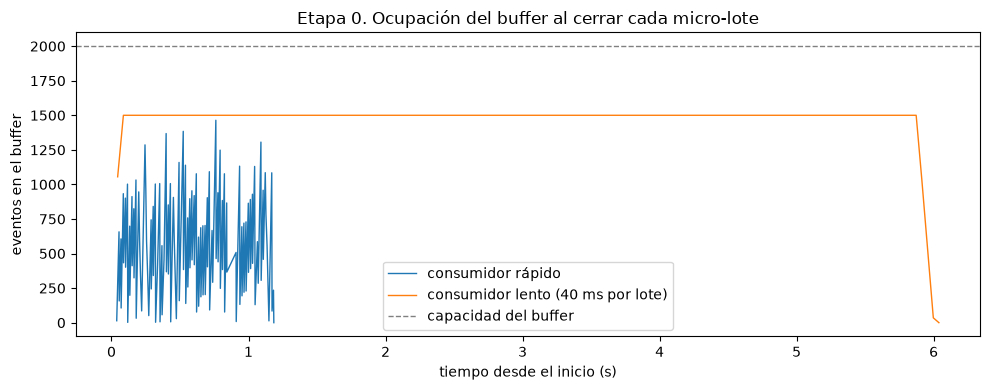

Ambos escenarios entregaron 71,535 eventos. El backpressure no perdió ninguno.


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lotes_rapido["t_s"], lotes_rapido["ocupacion_buffer"], label="consumidor rápido", lw=1)
ax.plot(lotes_lento["t_s"], lotes_lento["ocupacion_buffer"], label="consumidor lento (40 ms por lote)", lw=1)
ax.axhline(metricas_lento["capacidad"], color="gray", ls="--", lw=1, label="capacidad del buffer")
ax.set_xlabel("tiempo desde el inicio (s)")
ax.set_ylabel("eventos en el buffer")
ax.set_title("Etapa 0. Ocupación del buffer al cerrar cada micro-lote")
ax.legend()
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_ocupacion_buffer_{CATEGORIA}.png", dpi=150)
plt.show()

# Los dos escenarios procesan exactamente los mismos eventos (misma semilla)
assert metricas_rapido["eventos"] == metricas_lento["eventos"]
print(f"Ambos escenarios entregaron {metricas_rapido['eventos']:,} eventos. El backpressure no perdió ninguno.")

### Micro-lotes cerrados por tiempo

En los dos escenarios anteriores todos los lotes se cerraron por tamaño, porque el generador produce más de 500 eventos cada 50 ms. Para comprobar el cierre por tiempo se simula un stream de poco tráfico. Un productor pone un evento cada 2 ms, es decir, unos 25 eventos en cada ventana de 50 ms. Como el lote nunca alcanza 500 eventos, cada lote debe cerrarse por tiempo, y ningún evento debe esperar más de unos 50 ms en el buffer. En Windows la pausa real de time.sleep es algo mayor que 2 ms, por lo que cada lote reúne unos 20 eventos y no 25.

In [14]:
buffer_lento = BufferConBackpressure(capacidad=2_000)

def productor_poco_trafico(n_eventos=500, pausa_s=0.002):
    for i in range(n_eventos):
        buffer_lento.poner({"event_id": i, "llegada": time.perf_counter()})
        time.sleep(pausa_s)
    buffer_lento.cerrar()

hilo = threading.Thread(target=productor_poco_trafico, daemon=True)
hilo.start()
filas = []
for lote, motivo in micro_lotes(buffer_lento, tam_lote=500, max_espera_s=0.05):
    salida = time.perf_counter()
    filas.append({"tamano": len(lote), "motivo": motivo,
                  "espera_max_ms": (salida - min(e["llegada"] for e in lote)) * 1000})
hilo.join()

lotes_poco_trafico = pd.DataFrame(filas)
print(lotes_poco_trafico["motivo"].value_counts().to_dict())
lotes_poco_trafico.describe().round(1)

{'tiempo': 23, 'fin': 1}


,tamano,espera_max_ms
count,24.0,24.0
mean,20.8,48.4
std,1.5,3.1
min,15.0,35.5
25%,21.0,48.2
50%,21.0,48.9
75%,22.0,49.5
max,22.0,51.6


## Paso 8. Experimentos de complejidad

Los experimentos de complejidad de las colas (`ColaCircular` y `ColaEnlazada` frente a `list.pop(0)` y `collections.deque`, en tiempo y memoria) se hacen en un notebook aparte, `notebooks/experimentos_complejidad.ipynb`, porque llegan a 10 millones de elementos y tardan varios minutos. Ese notebook importa las mismas colas de `src/etapa_0/stage0_queue.py` que usa este notebook.

Resumen de los resultados, de 1K a 10M elementos con Python 3.12:

| Estructura | Pendiente log-log | Tiempo por operación a 10M | Memoria por elemento |
| --- | --- | --- | --- |
| `ColaCircular` (propia) | 0.95 | 317 ns | 8 B |
| `ColaEnlazada` (propia) | 0.95 | 317 ns | 48 B |
| `collections.deque` (C) | 0.95 | 60 ns | 8 B |
| `list.pop(0)` | 1.76 | 4 466 ns a 100K | 8 B |

Las colas propias cumplen O(1) por operación. `list.pop(0)` crece con n, como corresponde a O(n) por operación, y `deque` es unas 5 veces más rápida por estar escrita en C.

## Paso 9. Salida de la etapa 0 para la etapa 1

La etapa 0 entrega micro-lotes de registros crudos. Mientras cada etapa esté en su propio notebook, la salida se guarda en archivos dentro de `data/interim/<CATEGORIA>/`, que no se versiona. Las etapas 1 y 2 toman la misma carpeta de `src/config.py`. El notebook de la etapa 1 los leerá lote por lote.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa0_lotes.jsonl` | Una línea por micro-lote con su número y sus registros crudos | Etapa 1 |
| `etapa0_inyecciones.json` | Conteos de duplicados, malformados y tardíos inyectados (verdad de referencia) | Etapa 1, para medir la deduplicación y la validación |
| `listas_senalados.json` | Cuentas, tarjetas y dispositivos señalados | Etapa 6 (Bloom Filter) |

Se procesan las 1 500 000 reseñas de la ventana (`config.N_RESENAS`), que producen unos 10.5 millones de eventos. Los micro-lotes se escriben en el archivo a medida que salen del buffer, así que la memoria no crece con el número de eventos. La función `guardar_lote` cumple el papel de la etapa 1 dentro de `ejecutar_etapa0`, lo que muestra cómo se conectarán las etapas.

In [15]:
N_RESENAS_SALIDA = config.N_RESENAS
ruta_lotes = CARPETA_INTERIM / "etapa0_lotes.jsonl"

with open(ruta_lotes, "w", encoding="utf-8") as archivo_lotes:
    def guardar_lote(numero, lote):
        archivo_lotes.write(json.dumps({"lote": numero, "registros": lote}) + "\n")

    metricas_salida, lotes_salida, generador_salida = ejecutar_etapa0(
        N_RESENAS_SALIDA, al_recibir_lote=guardar_lote)

inyecciones = dict(generador_salida.estadisticas)
inyecciones.update(categoria=CATEGORIA, n_resenas=N_RESENAS_SALIDA, semilla=SEED,
                   porcentaje_tardios=config.PORCENTAJE_TARDIOS,
                   retraso_max_tardios_s=config.RETRASO_MAX_TARDIOS_S)
(CARPETA_INTERIM / "etapa0_inyecciones.json").write_text(json.dumps(inyecciones, indent=2), encoding="utf-8")
(CARPETA_INTERIM / "listas_senalados.json").write_text(
    json.dumps(generador_salida.listas_senalados(), indent=2), encoding="utf-8")

print(f"Archivo de lotes: {ruta_lotes.relative_to(RAIZ)}  ({ruta_lotes.stat().st_size / 1e9:.2f} GB)")
pd.Series(metricas_salida, name="valor").to_frame()

Archivo de lotes: data\interim\Office_Products\etapa0_lotes.jsonl  (3.31 GB)


,valor
eventos,10512167.00
lotes,21025.00
lotes_por_tamano,21024.00
lotes_por_tiempo,0.00
duracion_s,204.89
eventos_por_s,51307.00
bloqueos_productor,17452.00
espera_productor_s,52.04
ocupacion_maxima,2000.00
capacidad,2000.00


### Verificación de la salida

Se vuelve a leer el archivo para confirmar que el número de eventos guardados coincide con el número de eventos emitidos por el generador.

In [16]:
total_guardado = 0
with open(ruta_lotes, encoding="utf-8") as f:
    for linea in f:
        total_guardado += len(json.loads(linea)["registros"])

assert total_guardado == inyecciones["emitidos"] == metricas_salida["eventos"]
print(f"Eventos emitidos por el generador: {inyecciones['emitidos']:,}")
print(f"Eventos guardados en {metricas_salida['lotes']} lotes: {total_guardado:,}")
print("La etapa 0 entregó todos los eventos, sin pérdidas.")

Eventos emitidos por el generador: 10,512,167
Eventos guardados en 21025 lotes: 10,512,167
La etapa 0 entregó todos los eventos, sin pérdidas.


### Lectura de la ejecución completa

La etapa 0 entregó los 10 512 167 eventos de las 1 500 000 reseñas en 21 025 micro-lotes, sin perder ninguno, en 205 s (unos 51 000 eventos por segundo). Todos los lotes se cerraron por tamaño, salvo el último, porque el stream completo siempre tiene más de 500 eventos cada 50 ms.

El productor se bloqueó 17 452 veces, 52 s en total. En esta ejecución el consumidor no simula ningún costo, pero escribe cada lote en JSON, y eso es más lento que generar los eventos. El backpressure actuó también con un consumidor real: el buffer se llenó hasta su capacidad de 2 000 eventos, el productor esperó y la memoria quedó acotada.

## Resumen de la etapa 0

| Aspecto | Decisión |
| --- | --- |
| Lectura del dataset | Parquet leído por bloques con `iter_batches` dentro de una ventana reciente; memoria O(1) respecto al número de reseñas |
| Desorden | Controlado: 5 % de eventos tardíos con un retraso de hasta `RETRASO_MAX_TARDIOS_S`; sin tardíos el stream sale ordenado |
| Estructura del buffer | `ColaCircular` propia, capacidad fija, `encolar` y `desencolar` en O(1) |
| Estructura alternativa | `ColaEnlazada` propia, sin límite, para la cola de rechazados de la etapa 1 |
| Concurrencia | Productor en un hilo, consumidor en el hilo principal, sincronizados con `Lock` y `Condition` |
| Backpressure | El productor se bloquea si el buffer está lleno; no se pierden eventos y la memoria queda acotada |
| Micro-lotes | Se cierran al llegar a 500 eventos o al pasar 50 ms, lo que ocurra primero |
| Salida | Micro-lotes de registros crudos en `data/interim/<CATEGORIA>/etapa0_lotes.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 10. Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of Massive Datasets* (3.ª ed.), cap. 4.